In [4]:
from anemone.experiment import lamontagne, Waveform
import torch

def wv_to_t(t_eval, t_sampled, waveform=None):
    t_eval = t_eval.to(t_sampled.dtype)

    logT = torch.log(t_sampled)#.cpu()
    dT = logT[1]-logT[0]
    if waveform is None:
        t2t = lamontagne((torch.log(t_eval)[:,None]-logT[None,:])/dT)
    else:
        t2t = torch.zeros(t_eval.shape+t_sampled.shape, device=t_sampled.device, dtype=t_eval.dtype)

        for t_wv,k_wv in zip(waveform.time, waveform.d2wdt2):
            t2t += k_wv*lamontagne((torch.log(t_eval-t_wv)[:,None]-logT[None,:])/dT)
    return t2t

In [2]:
t = torch.logspace(-5, -3, 31)
ts = torch.logspace(-5.5, -2.5, 51)

t2t = wv_to_t(t, ts)

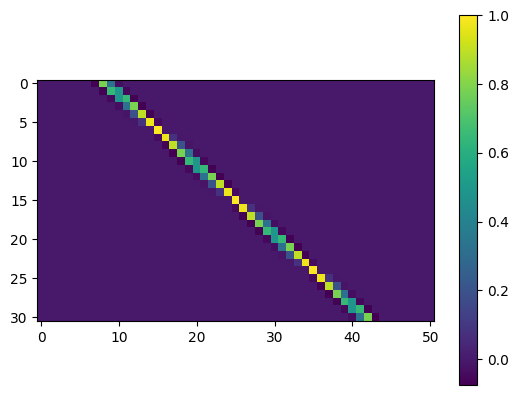

In [10]:
import matplotlib.pyplot as plt
import numpy as np
t2t = wv_to_t(t, ts)
plt.figure()
pcm=plt.imshow(t2t)
plt.colorbar(pcm)

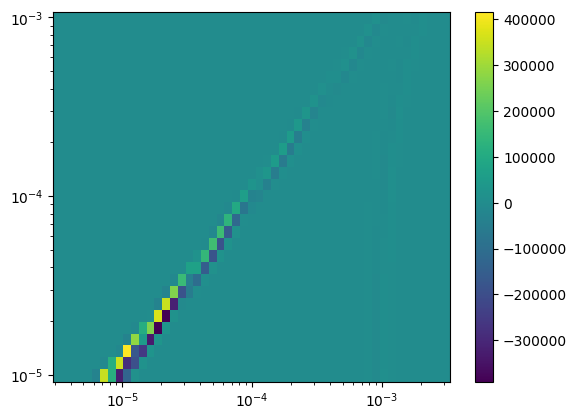

In [13]:
t2t = wv_to_t(t, ts, waveform=wv)
import matplotlib.pyplot as plt
import numpy as np
fig,ax = plt.subplots()
pcm=ax.pcolor(ts, t, t2t)
plt.colorbar(pcm)
ax.set_xscale('log')
ax.set_yscale('log')


In [5]:
wv = Waveform.example()

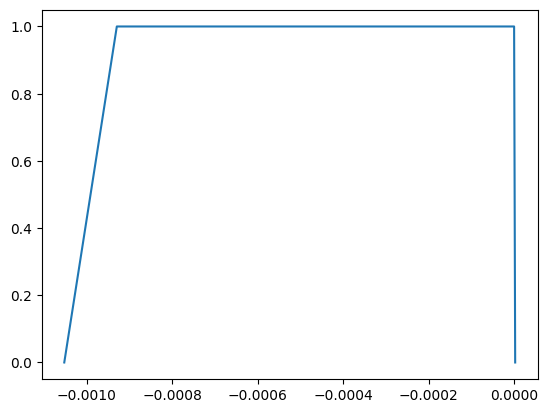

In [6]:
plt.figure()
plt.plot(wv.time, wv.amplitude)

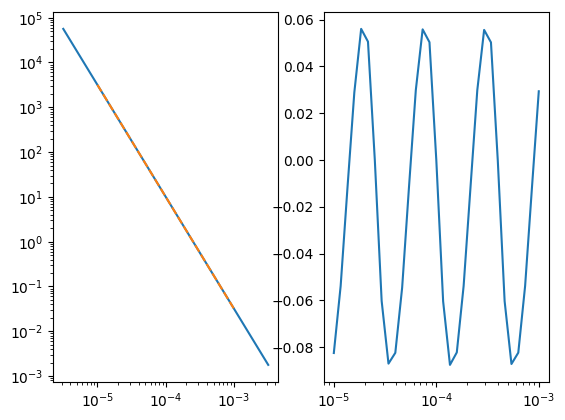

In [173]:
Hs = 1e-9*ts**(-5/2)

Hm = t2t@Hs
Ha = 1e-9*t**(-5/2)



fig,axs = plt.subplots(1,2)
axs[0].loglog(ts, Hs)
axs[0].loglog(t, Hm, '--')
axs[1].semilogx(t, 100*(Hm-Ha)/Ha)

In [174]:
from anemone.forwards import Forward
from anemone.transforms import *
from anemone.physics import refl_transverse_electric as rte, freespace_u0 as u0, colecole


\\bubi4.uni.au.dk\people\matt.griffiths\_git\anemone\src\anemone\experiment\experiment.py:125: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(overall_min)


pre-fourier HR shape torch.Size([481, 6])
pre-fourier r shape torch.Size([6])
pre-fourier post spatial shape torch.Size([481])
sampled times shape:  torch.Size([44])
shape of Ht:  torch.Size([44])
shape of t2t:  torch.Size([20, 44])


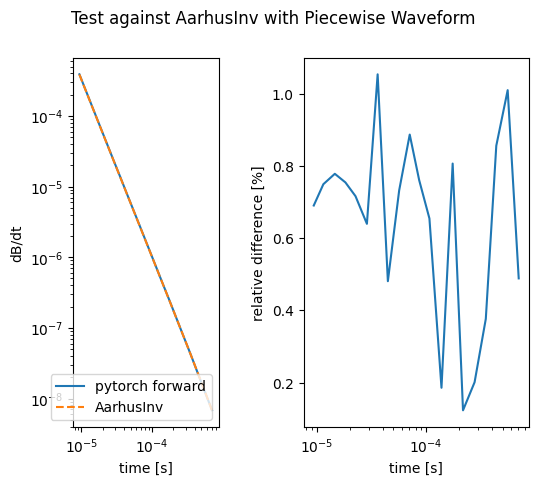

AssertionError: aarhus inv and pytorch forward do not match within 1/2 percent

In [175]:
from anemone.experiment import Loop, Receiver, Waveform
import torch


ainv_dbdt = torch.tensor([3.853627e-04, 2.309149e-04, 1.255715e-04, 7.168451e-05,
    4.196206e-05, 2.297534e-05, 1.302996e-05, 7.591422e-06,
    4.179841e-06, 2.394241e-06, 1.452859e-06, 8.455657e-07,
    4.466630e-07, 2.468966e-07, 1.423754e-07, 7.665493e-08,
    4.189503e-08, 2.367454e-08, 1.263738e-08, 6.809730e-09], dtype=torch.float64)

times = torch.tensor([9.350e-06, 1.145e-05, 1.458e-05, 1.822e-05, 2.255e-05, 2.867e-05, 3.595e-05, 4.460e-05, 5.660e-05, 7.070e-05, 8.630e-05, 1.071e-04,
    1.381e-04, 1.748e-04, 2.174e-04, 2.775e-04, 3.515e-04, 4.385e-04,
    5.575e-04, 7.035e-04])

t = torch.tensor([-1.0526e-03, -9.2963e-04,  0.0000e+00,  2.5000e-06])
wv = torch.tensor([0, 1, 1, 0])

waveform = Waveform(t, wv)


lp = Loop.square(40)
rx = Receiver()

rho = 40
sigma = 1/torch.tensor([rho,rho])
thick = torch.tensor([10])

fwr = Forward3(lp, rx, times, waveform=waveform)
dbdt = fwr(sigma, thick)
if __name__ == '__main__':
    import matplotlib.pyplot as plt
    fig,ax = plt.subplots(1,2, sharex=True)
    ax[0].loglog(fwr.times.numpy(), dbdt.real, label='pytorch forward')
    ax[0].loglog(times,      ainv_dbdt, '--', label='AarhusInv')
    ax[0].set_ylabel('dB/dt')
    ax[0].legend()
    ax[0].set_aspect('equal')

    ax[1].semilogx(times, 100*torch.abs(dbdt.real-ainv_dbdt)/torch.abs(ainv_dbdt))
    ax[1].set_ylabel('relative difference [%]')
    for ax_ in ax:
        ax_.set_xlabel('time [s]')

    fig.suptitle('Test against AarhusInv with Piecewise Waveform')
    plt.show()
assert torch.allclose(ainv_dbdt, dbdt, rtol=0.5e-2), "aarhus inv and pytorch forward do not match within 1/2 percent"

In [223]:
from anemone.forwards import Forward, wv_to_t
from anemone.transforms import *
from anemone.physics import refl_transverse_electric as rte, freespace_u0 as u0, colecole

class Forward3(Forward):
    sofr=None
    t2t =None
    
    def forward(self):
        def frq_integrand(f):
            omega = c.twopi*f[None,:,None]

            def wvlngth_integrand(wave_length):
                """ Hz from horizontal electric dipole. """
                lmb = wave_length[None, None, :]
                
                tmp_u0 = u0(omega, lmb)
                intg = torch.exp(-tmp_u0*self.pfield_dz)+rte(self.sigma, self.thick, omega, lmb)*torch.exp(-tmp_u0*self.sfield_dz)
                intg *= lmb**2 / tmp_u0
            
                if self.filterfunc is not None:
                    intg *= self.filterfunc.omega_filter(omega)
                return torch.squeeze(intg/c.fourpi)
            
            hkl1 = Hankel(wvlngth_integrand, 1, device=self.device, tolerance=1e-6)
            r,HR = hkl1._range(self.rmin, self.rmax)
            # print('pre-fourier HR shape', HR.shape)
            # print('pre-fourier r shape', r.shape)
            if self.sofr is None:
                self.sofr = self.source.s_of_r(self.receiver, r).to(torch.complex128)
            res = torch.einsum('...i,...i', HR, self.sofr)
            if self.waveform is not None:
                res /= -1j*omega.squeeze()
            # print('pre-fourier post spatial shape', res.shape)
            return res
        
        cbft=invFourier(frq_integrand, smp_per_decade=10, device=self.device)
        self.t_sampled,Ht = cbft.range(self.tmin, self.tmax)
        # print('sampled times shape: ', self.t_sampled.shape)

        if self.t2t is None:
            self.t2t = wv_to_t(self.times, self.t_sampled, waveform=self.waveform)

        if len(Ht.shape)==1:
            return torch.einsum('...i,...i', Ht.real, self.t2t)
        else:
            return torch.einsum('...ik,...jk->...ij', Ht.real, self.t2t)
    

In [224]:
import torch
import matplotlib.pyplot as plt
import numpy as np

from anemone.experiment import Loop, Receiver, compute_relstd, Waveform
from anemone.forwards import Forward2
from anemone.inversion import *

tx = Loop.square(25)
rx = Receiver()
t = torch.logspace(-5, -3.5, 32, dtype=torch.double)
wv = Waveform.example()


gpu = torch.device('cpu')
fwr  =Forward3(tx, rx, t.to(gpu), waveform=wv)
fwr0 =Forward2(tx, rx, t.to(gpu), waveform=wv)

In [225]:
rho = torch.ones(31)*40
rho[5:25] = 100
thk = torch.logspace(-1, 1, 31-1)

dbdt = fwr(1./rho, thk)
dbdt0=fwr0(1./rho, thk)

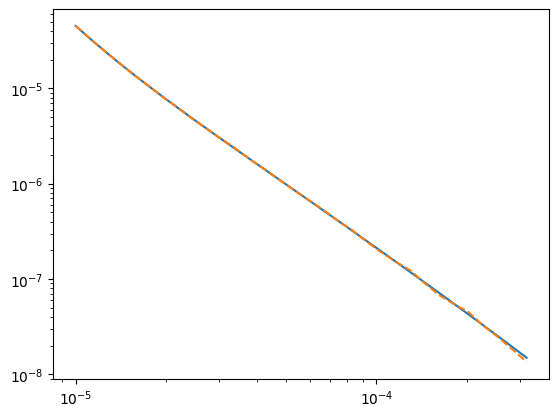

In [226]:
plt.figure()
plt.loglog(fwr.times, dbdt0)
plt.loglog(fwr.times, dbdt, '--')


cpu
torch.Size([10, 32])


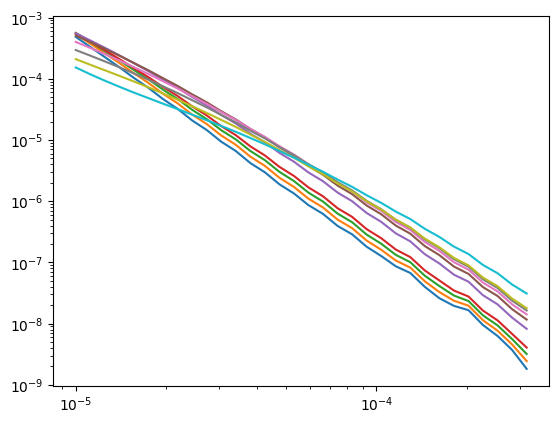

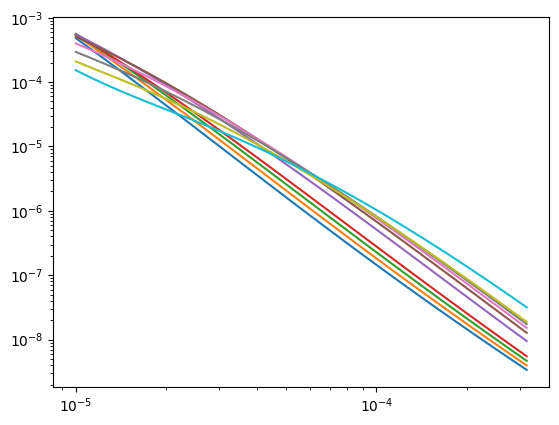

In [227]:
import torch
import matplotlib.pyplot as plt
import numpy as np

from anemone.experiment import Loop, Receiver, compute_relstd, Waveform
from anemone.inversion import *

tx = Loop.square(25)
rx = Receiver()


gpu = torch.device('cpu')
# fwr = Forward3(tx, rx, t.to(gpu), waveform=Waveform.example())
print(fwr.device)

n_layers = 31
thick = torch.logspace(-1, 1, n_layers-1).to(gpu)


z = np.arange(n_layers)[:,None]
x = 30*np.arange(10)[None,:]

rho = 300*np.ones_like(z+x)
rho[(0.03*x-0.75*z+10)>0] = 10
rho[(0.075*x-1.25*z+5)>0] = 40


sigma = torch.from_numpy(1./rho).to(gpu)
thick = torch.logspace(-1, 1, len(z)-1).to(gpu)

dbdt = fwr(sigma,thick)
ct = fwr.times
print(dbdt.shape)

plt.figure()
plt.loglog(ct, dbdt.cpu().T)

dbdt=fwr0(sigma,thick)
ct = fwr.times

plt.figure()
plt.loglog(ct, dbdt.cpu().T)

In [228]:
%%timeit
dbdt = fwr0(sigma, thick)

2.29 s ± 717 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [229]:
%%timeit
dbdt = fwr(sigma,thick)

The slowest run took 4.44 times longer than the fastest. This could mean that an intermediate result is being cached.
334 ms ± 184 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [78]:
print('shape of data is :', dbdt.shape)
# should be >>> shape of data is : torch.Size([10, 16])



n_data = len(dbdt.T.flatten())

def transform(d, skip_log=False):
    if skip_log:
        return d.reshape((-1,n_data)).squeeze()
    else:
        return torch.log10(torch.abs(d.reshape((-1,n_data)).squeeze()))


dbdt_err = compute_relstd(fwr.times, dbdt)
dbdt_err5 = compute_relstd(fwr.times, dbdt, relative_noise=0.03)

m_start = m_true.copy()
m_start.values[0] = torch.ones_like(m_start.values[0])*0.02

dbdt_obs = transform(torch.abs(dbdt + dbdt*dbdt_err*torch.randn(dbdt.shape,device=gpu)), skip_log=True)
dbdt_err5 = transform(dbdt*dbdt_err5, skip_log=True)


inv = LCI(dbdt_obs, dbdt_err5, m_start, fwr, data_transform=transform)
inv.data_misfit_acceptance_threshold = 0.9
print('fwr device is ', fwr.device)
invm1 = inv.m*1.
invm1[20:25] *= 1.1
dbdt_flat0 = inv.mforward(inv.m)
dbdt_flat1 = inv.mforward(invm1)

# plt.figure()
# plt.plot(dbdt_flat0.numpy())
# plt.plot(dbdt_flat1.numpy())
# plt.show()
from time import perf_counter
t0 = perf_counter()
res_mod = inv.invert(smoothness=1e3, iter_cap=20)
delta_t = perf_counter()-t0

if __name__ == '__main__':
    print(f'inversion took {delta_t:.2f} seconds.')
    fig,axs = plt.subplots(2,1,sharex=True, sharey=True)
    m_true.plot(ax=axs[0], vmin=1, vmax=2.5, cmap='turbo')
    res_mod.plot(ax=axs[1], vmin=1, vmax=2.5, cmap='turbo')
    plt.show() 
    
assert inv.misfits[-1] < 1, "misfit is not below one."

shape of data is : torch.Size([31])


RuntimeError: The size of tensor a (16) must match the size of tensor b (31) at non-singleton dimension 0